In [1]:
!pip install tabpfn

In [2]:
import kagglehub
import random
import numpy as np
import torch
import pandas as pd
import os
import sys
import shutil
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from tabpfn import TabPFNClassifier

In [3]:
def set_seed(seed=42):
    """
    Configura la semilla en todas las librerías para garantizar
    la reproducibilidad absoluta del laboratorio.
    """
    # 1. Python nativo
    random.seed(seed)

    # 2. NumPy (operaciones matriciales y EDA)
    np.random.seed(seed)

    # 3. PyTorch (Backend que utiliza TabPFN)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed) # Por si ejecutan en entornos multi-GPU

    # 4. Forzar a PyTorch a usar algoritmos deterministas
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"✅ ¡Semilla global configurada en {seed}! Entorno 100% reproducible.")

# Ejecutar la función antes de preparar los datos
set_seed(42)

✅ ¡Semilla global configurada en 42! Entorno 100% reproducible.


In [17]:

def descargar_y_guardar_dataset(kaggle_id, nombre_archivo_local):
    """
    Intenta descargar un dataset de Kaggle. Si funciona, guarda una copia local.
    Si falla (ej. sin internet), intenta cargar la copia local de respaldo.
    """
    # Crear una carpeta para guardar los respaldos locales si no existe
    os.makedirs("datasets_respaldo", exist_ok=True)
    ruta_respaldo = os.path.join("datasets_respaldo", nombre_archivo_local)

    try:
        print(f"Intentando descargar '{kaggle_id}' desde Kaggle...")
        # Intentar descargar la última versión
        path = kagglehub.dataset_download(kaggle_id)

        # Buscar el archivo .csv dentro de la ruta descargada
        archivo_csv = [f for f in os.listdir(path) if f.endswith('.csv')][0]
        ruta_original = os.path.join(path, archivo_csv)

        # Guardar (copiar) el dataset en nuestra carpeta de respaldo
        shutil.copy(ruta_original, ruta_respaldo)
        print(f"✅ Descarga exitosa. Dataset guardado en: {ruta_respaldo}")

        # Cargar en un DataFrame
        return pd.read_csv(ruta_respaldo)

    except Exception as e:
        # ¡Aquí se configura el error si Kaggle deja de funcionar!
        print(f"⚠️ Error al conectar con Kaggle o descargar: {e}")
        print("Buscando copia de respaldo local...")

        # Fallback (Plan B): Intentar usar el archivo guardado previamente
        if os.path.exists(ruta_respaldo):
            print(f"✅ ¡Respaldo encontrado! Cargando desde: {ruta_respaldo}")
            return pd.read_csv(ruta_respaldo)
        else:
            print(f"❌ Error Crítico: No hay internet y no se encontró el archivo '{nombre_archivo_local}' en el respaldo local.")
            # Retornar None o lanzar el error según prefieras
            raise FileNotFoundError("Imposible cargar los datos. Verifica tu conexión a internet para la primera descarga.")

# ---------------------------------------------------------
# 1. Cargar Crop Recommendation Dataset
# ---------------------------------------------------------
print("--- DATASET 1: CROP RECOMMENDATION ---")
df_crop = descargar_y_guardar_dataset(
    kaggle_id="atharvaingle/crop-recommendation-dataset",
    nombre_archivo_local="crop_recommendation.csv"
)

if df_crop is not None:
    print("\nVista previa de CROP RECOMMENDATION")
    display(df_crop.head(2))
# ---------------------------------------------------------
# 2. Cargar German Credit Dataset
# ---------------------------------------------------------
print("\n--- DATASET 2: GERMAN CREDIT ---")
df_german = descargar_y_guardar_dataset(
    kaggle_id="kabure/german-credit-data-with-risk",
    nombre_archivo_local="german_credit_data.csv"
)

# Mostrar un vistazo rápido a los datos si se cargaron correctamente
if df_german is not None:
    print("\nVista previa de German Credit:")
    display(df_german.head(2))

--- DATASET 1: CROP RECOMMENDATION ---
Intentando descargar 'atharvaingle/crop-recommendation-dataset' desde Kaggle...
Using Colab cache for faster access to the 'crop-recommendation-dataset' dataset.
✅ Descarga exitosa. Dataset guardado en: datasets_respaldo/crop_recommendation.csv

Vista previa de CROP RECOMMENDATION


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice



--- DATASET 2: GERMAN CREDIT ---
Intentando descargar 'kabure/german-credit-data-with-risk' desde Kaggle...


100%|██████████| 11.2k/11.2k [00:00<00:00, 21.9MB/s]

Extracting files...
✅ Descarga exitosa. Dataset guardado en: datasets_respaldo/german_credit_data.csv

Vista previa de German Credit:


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad


In [18]:
print("--- RADIOGRAFÍA DEL DATASET GERMAN CREDIT ---")

# 1. Ver la cantidad total de filas y columnas
print(f"Dimensiones del dataset: {df_german.shape[0]} filas y {df_german.shape[1]} columnas\n")

# 2. Listar cada columna con su tipo de dato exacto
print("📋 COLUMNAS Y TIPOS DE DATOS DETECTADOS:")
print("-" * 50)
for col, dtype in df_german.dtypes.items():
    print(f"➡️ Columna: {col:<20} | Tipo de dato: {dtype}")
print("-" * 50)

# 3. Mostrar las primeras 3 filas para ver una muestra real del contenido
print("\n👀 VISTA PREVIA DE LOS DATOS (PRIMERAS 3 FILAS):")
display(df_german.head(3))

--- RADIOGRAFÍA DEL DATASET GERMAN CREDIT ---
Dimensiones del dataset: 1000 filas y 11 columnas

📋 COLUMNAS Y TIPOS DE DATOS DETECTADOS:
--------------------------------------------------
➡️ Columna: Unnamed: 0           | Tipo de dato: int64
➡️ Columna: Age                  | Tipo de dato: int64
➡️ Columna: Sex                  | Tipo de dato: object
➡️ Columna: Job                  | Tipo de dato: int64
➡️ Columna: Housing              | Tipo de dato: object
➡️ Columna: Saving accounts      | Tipo de dato: object
➡️ Columna: Checking account     | Tipo de dato: object
➡️ Columna: Credit amount        | Tipo de dato: int64
➡️ Columna: Duration             | Tipo de dato: int64
➡️ Columna: Purpose              | Tipo de dato: object
➡️ Columna: Risk                 | Tipo de dato: object
--------------------------------------------------

👀 VISTA PREVIA DE LOS DATOS (PRIMERAS 3 FILAS):


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good


In [19]:
print("\nIniciando preprocesamiento para GERMAN CREDIT...")

# 2. Limpieza inicial: borrar índice basura si existe
if 'Unnamed: 0' in df_german.columns:
    df_german = df_german.drop(columns=['Unnamed: 0'])

# 3. Separar características (X) y objetivo (y)
columna_objetivo = 'Risk'
print(f"🎯 Variable objetivo: '{columna_objetivo}'")

df_processed = df_german.dropna(subset=[columna_objetivo]).copy()
X = df_processed.drop(columns=[columna_objetivo])
y = df_processed[columna_objetivo]

# 4. Codificar la variable objetivo (good/bad -> 1/0)
le = LabelEncoder()
y = le.fit_transform(y)
print(f"✅ Clases reales detectadas: {le.classes_} -> transformadas a [0, 1]")

# 5. Manejo de valores nulos (NaNs en cuentas bancarias)
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
numeric_cols = X.select_dtypes(include=['number']).columns

if len(categorical_cols) > 0:
    X[categorical_cols] = X[categorical_cols].fillna('Desconocido')
if len(numeric_cols) > 0:
    X[numeric_cols] = X[numeric_cols].fillna(X[numeric_cols].median())

# 6. Codificación de variables categóricas (Sex, Housing, Purpose, etc.)
if len(categorical_cols) > 0:
    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    X[categorical_cols] = encoder.fit_transform(X[categorical_cols].astype(str))

# 7. División de datos (Train/Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("✅ Datos completamente limpios y listos para entrenar.")


Iniciando preprocesamiento para GERMAN CREDIT...
🎯 Variable objetivo: 'Risk'
✅ Clases reales detectadas: ['bad' 'good'] -> transformadas a [0, 1]
✅ Datos completamente limpios y listos para entrenar.


In [20]:
# Para que el benchmark sea válido en tu celda de métricas, dejamos el modelo de tu compañero corriendo aquí
print("Entrenando modelos clásicos de la Parte 1 para la comparativa...")

# Random Forest con la misma semilla para una comparación justa
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Predicciones del modelo clásico
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("✅ Modelos de referencia listos.")

Entrenando modelos clásicos de la Parte 1 para la comparativa...
✅ Modelos de referencia listos.


In [21]:
# 1. Configurar tu token de forma obligatoria
os.environ["TABPFN_TOKEN"] = "tabpfn_sk_iPZbyLLnlUZKB1kKSHFg2Qu62IHXdl_NdvX8bGbL6V8"

# 2. Forzar por variable de entorno que permita datasets grandes (Medida de seguridad MLOps)
os.environ["TABPFN_ALLOW_CPU_LARGE_DATASET"] = "1"

# 3. BORRADO PROFUNDO: Eliminamos la raíz y TODOS los sub-módulos ocultos de la caché
modulos_a_borrar = [mod for mod in sys.modules.keys() if mod.startswith('tabpfn')]
for modulo in modulos_a_borrar:
    del sys.modules[modulo]

# 4. Ahora sí, importamos la librería completamente limpia y con el token activo
from tabpfn import TabPFNClassifier

print("Iniciando TabPFN... Cargando pesos preentrenados del Transformer en la GPU.")

# 5. Inicializamos el clasificador eliminando 'device=cpu' para que detecte la GPU por defecto
# Agregamos ignore_pretraining_limits=True para evitar bloqueos de tamaño
tabpfn_model = TabPFNClassifier(ignore_pretraining_limits=True)

# 6. In-Context Learning en GPU
tabpfn_model.fit(X_train, y_train)

# 7. Generar predicciones en el conjunto de prueba
y_pred_pfn = tabpfn_model.predict(X_test)
y_prob_pfn = tabpfn_model.predict_proba(X_test)[:, 1]

print("✅ ¡LOGRADO! Inferencia con TabPFN finalizada con éxito utilizando la GPU.")

Iniciando TabPFN... Cargando pesos preentrenados del Transformer en la GPU.
✅ ¡LOGRADO! Inferencia con TabPFN finalizada con éxito utilizando la GPU.


Calculando métricas comparativas...

MÉTRICA         | RANDOM FOREST | TabPFN    
Accuracy        | 0.7300        | 0.7667    
F1-Score (Macro) | 0.6208        | 0.6771    
ROC-AUC         | 0.7280        | 0.7696    


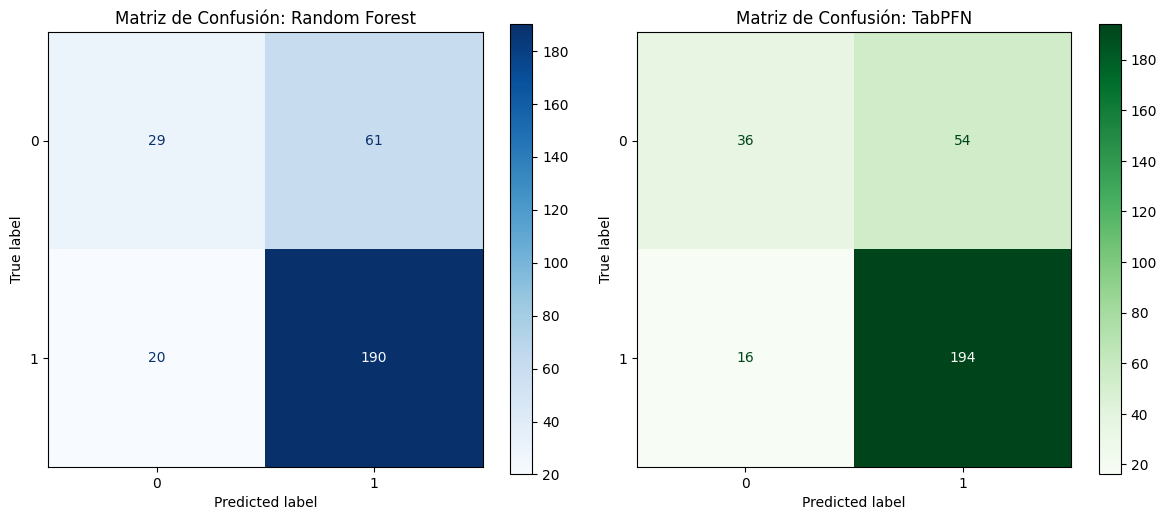

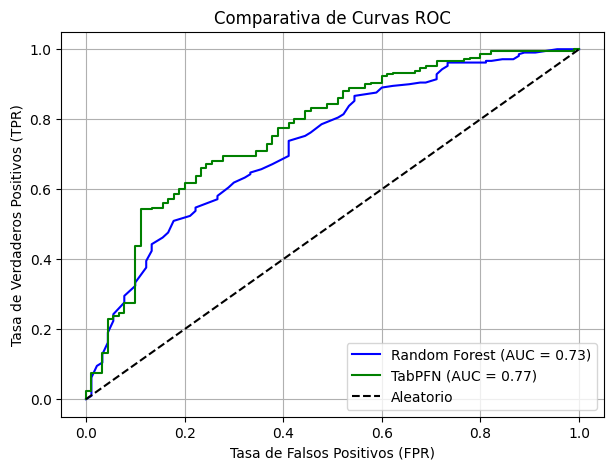

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve

print("Calculando métricas comparativas...")

# 1. Detectar automáticamente si es binario o multiclase
num_classes = len(np.unique(y_test))
is_multiclass = num_classes > 2

# 2. Extraer probabilidades completas directamente de los modelos en memoria
probs_rf_full = rf_model.predict_proba(X_test)
probs_pfn_full = tabpfn_model.predict_proba(X_test)

# 3. Calcular Accuracy y F1-Score (Funciona igual para ambos)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average='macro')

accuracy_pfn = accuracy_score(y_test, y_pred_pfn)
f1_pfn = f1_score(y_test, y_pred_pfn, average='macro')

# 4. Calcular ROC-AUC dinámicamente
if is_multiclass:
    # Matemática para Multiclase (One-vs-Rest)
    roc_auc_rf = roc_auc_score(y_test, probs_rf_full, multi_class='ovr')
    roc_auc_pfn = roc_auc_score(y_test, probs_pfn_full, multi_class='ovr')
else:
    # Matemática para Binario (Solo tomamos la columna de la clase 1)
    roc_auc_rf = roc_auc_score(y_test, probs_rf_full[:, 1])
    roc_auc_pfn = roc_auc_score(y_test, probs_pfn_full[:, 1])

# --- MOSTRAR TABLA DE RESULTADOS ---
print("\n" + "="*45)
print(f"{'MÉTRICA':<15} | {'RANDOM FOREST':<13} | {'TabPFN':<10}")
print("="*45)
print(f"{'Accuracy':<15} | {accuracy_rf:<13.4f} | {accuracy_pfn:<10.4f}")
print(f"{'F1-Score (Macro)':<15} | {f1_rf:<13.4f} | {f1_pfn:<10.4f}")
print(f"{'ROC-AUC':<15} | {roc_auc_rf:<13.4f} | {roc_auc_pfn:<10.4f}")
print("="*45)

# --- GRAFICAR MATRICES DE CONFUSIÓN ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp_rf.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title("Matriz de Confusión: Random Forest")

cm_pfn = confusion_matrix(y_test, y_pred_pfn)
disp_pfn = ConfusionMatrixDisplay(confusion_matrix=cm_pfn)
disp_pfn.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title("Matriz de Confusión: TabPFN")

plt.tight_layout()
plt.show()

# --- GRAFICAR CURVA ROC (Solo si es Binario) ---
if is_multiclass:
    print(f"\n⚠️ Nota MLOps: Se detectaron {num_classes} clases. La gráfica de Curva ROC tradicional se omite porque solo aplica a problemas binarios.")
else:
    plt.figure(figsize=(7, 5))
    fpr_rf, tpr_rf, _ = roc_curve(y_test, probs_rf_full[:, 1])
    fpr_pfn, tpr_pfn, _ = roc_curve(y_test, probs_pfn_full[:, 1])

    plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.2f})', color='blue')
    plt.plot(fpr_pfn, tpr_pfn, label=f'TabPFN (AUC = {roc_auc_pfn:.2f})', color='green')
    plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio')

    plt.xlabel('Tasa de Falsos Positivos (FPR)')
    plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
    plt.title('Comparativa de Curvas ROC')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

In [9]:
import joblib
from google.colab import files

print("📦 Guardando y descargando artefactos del Dataset de Crédito...")

# 1. Guardar los modelos en el almacenamiento local de Colab
joblib.dump(rf_model, 'modelo_rf_credito.pkl')
joblib.dump(tabpfn_model, 'modelo_tabpfn_credito.pkl')

print("💾 Archivos .pkl creados con éxito. Iniciando descarga automática...")

# 2. Forzar la descarga directa al navegador
files.download('modelo_rf_credito.pkl')
files.download('modelo_tabpfn_credito.pkl')

print("✅ Descargas del dataset de crédito iniciadas.")

📦 Guardando y descargando artefactos del Dataset de Crédito...
💾 Archivos .pkl creados con éxito. Iniciando descarga automática...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Descargas del dataset de crédito iniciadas.


#Dataset

In [10]:
print("Iniciando preprocesamiento para CROP RECOMMENDATION...")

# 1. Limpieza inicial: eliminar columnas de índices si existen
if 'Unnamed: 0' in df_crop.columns:
    df_crop = df_crop.drop(columns=['Unnamed: 0'])

# 2. Identificar la columna objetivo dinámicamente ('label' es la estándar en este dataset)
posibles_targets_crop = ['label', 'Risk', 'Class', 'target']
target_col_crop = next((col for col in posibles_targets_crop if col in df_crop.columns), df_crop.columns[-1])

print(f"Columna objetivo detectada: '{target_col_crop}'")

# Copia de trabajo para no alterar el dataset original
df_processed_crop = df_crop.copy()

# Eliminar filas donde el TARGET sea nulo (medida de seguridad)
df_processed_crop = df_processed_crop.dropna(subset=[target_col_crop])

X_crop = df_processed_crop.drop(columns=[target_col_crop])
y_crop = df_processed_crop[target_col_crop]

# 3. Codificar la variable objetivo AUTOMÁTICAMENTE (Nombres de cultivos -> Números)
le_crop = LabelEncoder()
y_crop = le_crop.fit_transform(y_crop)
print(f"Cultivos detectados en target: {len(le_crop.classes_)} clases distintas.")

# 4. Manejo de NaNs en las características (suelo, clima, etc.)
categorical_cols_crop = X_crop.select_dtypes(include=['object', 'category']).columns
numeric_cols_crop = X_crop.select_dtypes(include=['number']).columns

# Rellenar nulos de forma dinámica
if len(categorical_cols_crop) > 0:
    X_crop[categorical_cols_crop] = X_crop[categorical_cols_crop].fillna('Desconocido')
if len(numeric_cols_crop) > 0:
    X_crop[numeric_cols_crop] = X_crop[numeric_cols_crop].fillna(X_crop[numeric_cols_crop].median())

# 5. Codificación de variables categóricas para TabPFN
if len(categorical_cols_crop) > 0:
    encoder_crop = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    X_crop[categorical_cols_crop] = encoder_crop.fit_transform(X_crop[categorical_cols_crop].astype(str))

# 6. Partición de datos exacta (Estratificada por tipo de cultivo)
X_train_crop, X_test_crop, y_train_crop, y_test_crop = train_test_split(
    X_crop, y_crop,
    test_size=0.3,
    random_state=42,
    stratify=y_crop
)

print("✅ Preprocesamiento completado. Datos listos para Crop Dataset.")
print(f"Dimensiones finales -> Train: {X_train_crop.shape} | Test: {X_test_crop.shape}")

Iniciando preprocesamiento para CROP RECOMMENDATION...
Columna objetivo detectada: 'label'
Cultivos detectados en target: 22 clases distintas.
✅ Preprocesamiento completado. Datos listos para Crop Dataset.
Dimensiones finales -> Train: (1540, 7) | Test: (660, 7)


In [11]:
# Para que el benchmark sea válido en tu celda de métricas, dejamos el modelo de tu compañero corriendo aquí para CROP
print("Entrenando modelos clásicos de la Parte 1 para la comparativa (Crop Recommendation)...")

# Random Forest con la misma semilla para una comparación justa en formato multiclase
rf_model_crop = RandomForestClassifier(random_state=42)
rf_model_crop.fit(X_train_crop, y_train_crop)

# Predicciones del modelo clásico para el dataset de cultivos
y_pred_rf_crop = rf_model_crop.predict(X_test_crop)

# NOTA: Al ser un problema MULTICLASE, guardamos la matriz de probabilidades completa
# (No usamos el [:, 1] del dataset binario porque aquí hay múltiples cultivos posibles)
y_prob_rf_crop = rf_model_crop.predict_proba(X_test_crop)

print("✅ Modelos de referencia listos para Crop Dataset.")

Entrenando modelos clásicos de la Parte 1 para la comparativa (Crop Recommendation)...
✅ Modelos de referencia listos para Crop Dataset.


In [12]:
print("Iniciando TabPFN para Crop Recommendation (In-Context Learning Multiclase)...")

# 1. El token ya está configurado en el entorno de la celda anterior, no es necesario hacer borrado profundo de nuevo.
# 2. Inicializamos el clasificador para el nuevo set de datos
tabpfn_model_crop = TabPFNClassifier()

# 3. In-Context Learning: Pasamos los datos del dataset de cultivos
tabpfn_model_crop.fit(X_train_crop, y_train_crop)

# 4. Generar predicciones en el conjunto de prueba de cultivos
y_pred_pfn_crop = tabpfn_model_crop.predict(X_test_crop)

# NOTA MULTICLASE: Guardamos la matriz de probabilidades completa para todas las clases de cultivos
# (Quitamos el [:, 1] porque ya no es una clasificación binaria)
y_prob_pfn_crop = tabpfn_model_crop.predict_proba(X_test_crop)

print("✅ ¡LOGRADO! Inferencia con TabPFN finalizada con éxito para Crop Dataset.")

Iniciando TabPFN para Crop Recommendation (In-Context Learning Multiclase)...
✅ ¡LOGRADO! Inferencia con TabPFN finalizada con éxito para Crop Dataset.


Calculando métricas comparativas para el Dataset de Cultivos...

MÉTRICA (CROP DATASET)    | RANDOM FOREST | TabPFN    
Accuracy                  | 0.9939        | 0.9924    
F1-Score (Macro)          | 0.9939        | 0.9924    
ROC-AUC (OVR Macro)       | 0.999990      | 0.999990  


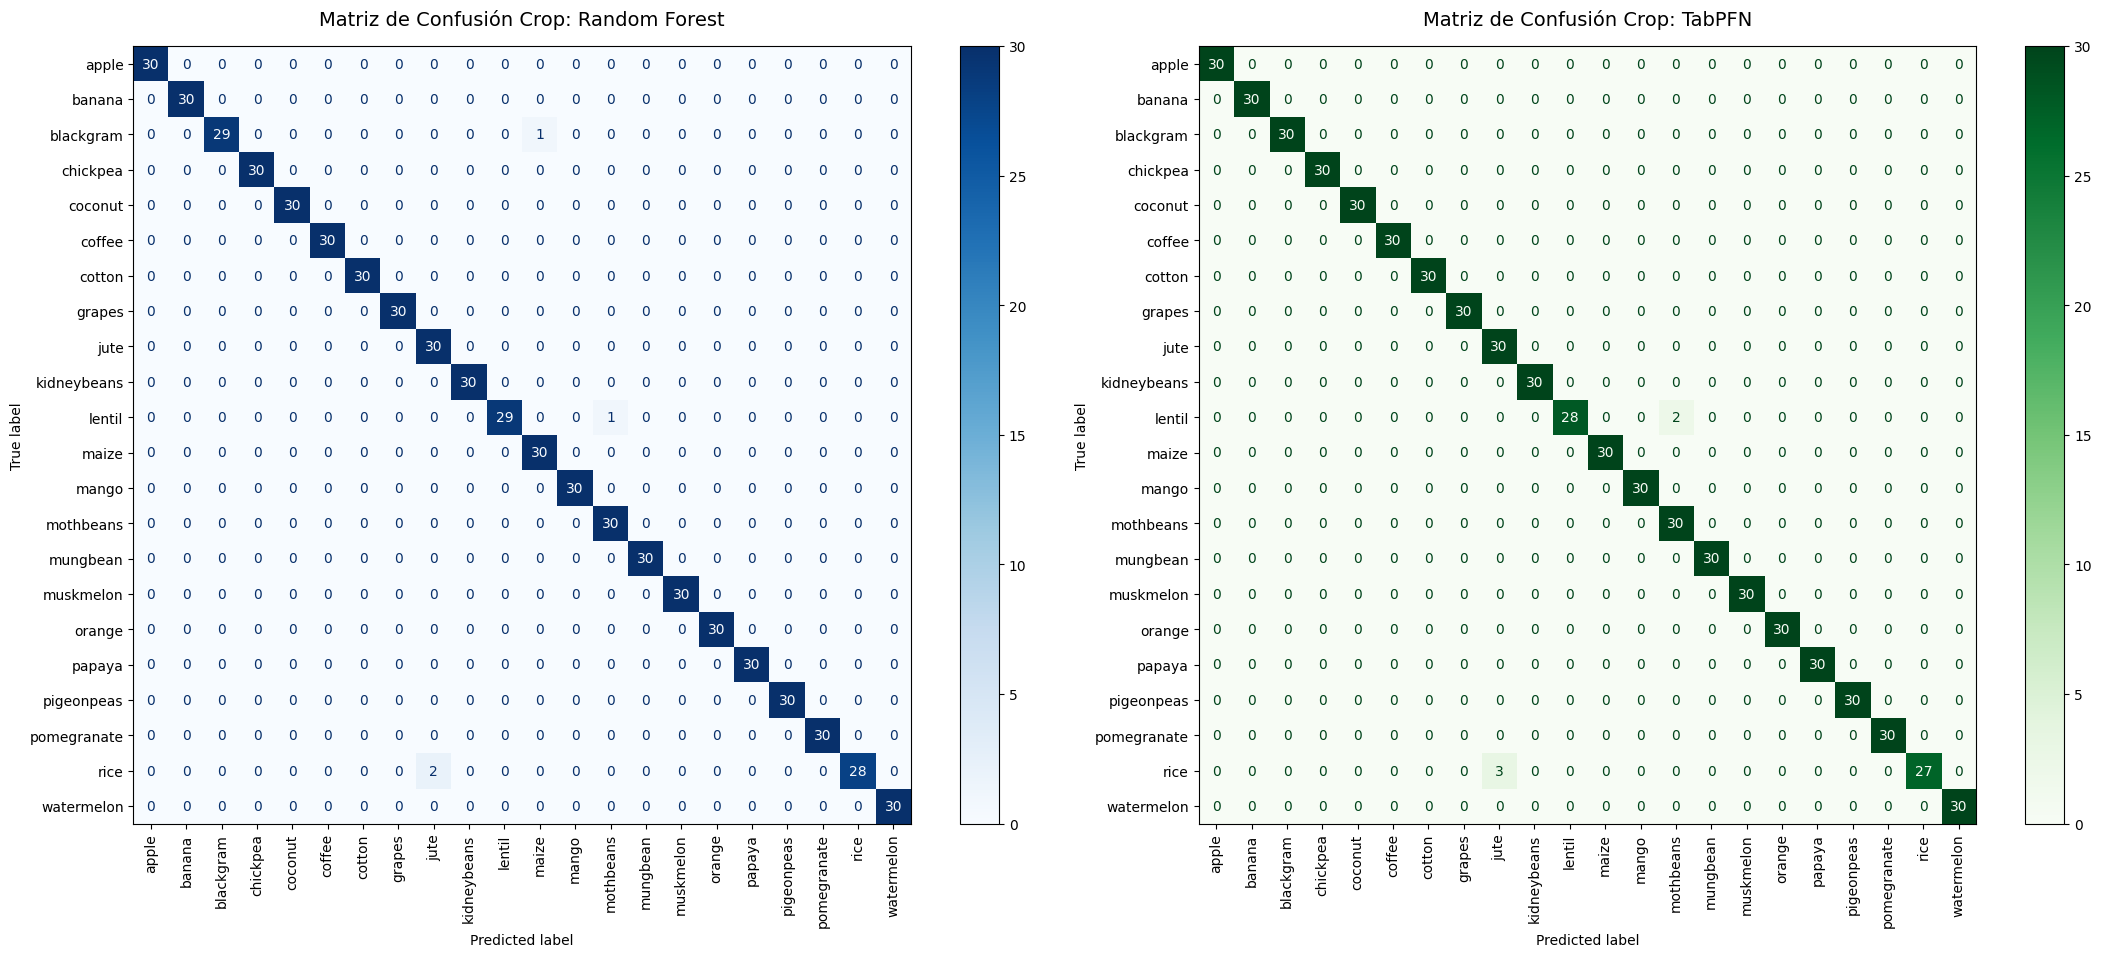


⚠️ Nota MLOps: Se detectaron 22 clases correspondientes a distintos tipos de cultivos.
La gráfica de la curva ROC tradicional (2D) se omite de forma visual porque el espacio conceptual es multiclase.
Su equivalencia matemática exacta (Área bajo la curva promedio ponderada macro OVR) está calculada arriba en la tabla.


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

print("Calculando métricas comparativas para el Dataset de Cultivos...")

# 1. Detectar automáticamente si el dataset de cultivos es binario o multiclase
num_classes_crop = len(np.unique(y_test_crop))
is_multiclass_crop = num_classes_crop > 2

# 2. Calcular Accuracy y F1-Score (Macro es ideal para multiclase balanceado)
accuracy_rf_c = accuracy_score(y_test_crop, y_pred_rf_crop)
f1_rf_c = f1_score(y_test_crop, y_pred_rf_crop, average='macro')

accuracy_pfn_c = accuracy_score(y_test_crop, y_pred_pfn_crop)
f1_pfn_c = f1_score(y_test_crop, y_pred_pfn_crop, average='macro')

# 3. Calcular ROC-AUC multiclase dinámicamente usando la estrategia One-vs-Rest (OVR)
if is_multiclass_crop:
    roc_auc_rf_c = roc_auc_score(y_test_crop, y_prob_rf_crop, multi_class='ovr', average='macro')
    roc_auc_pfn_c = roc_auc_score(y_test_crop, y_prob_pfn_crop, multi_class='ovr', average='macro')
else:
    roc_auc_rf_c = roc_auc_score(y_test_crop, y_prob_rf_crop[:, 1])
    roc_auc_pfn_c = roc_auc_score(y_test_crop, y_prob_pfn_crop[:, 1])

# --- MOSTRAR TABLA DE RESULTADOS PARA CROP ---
print("\n" + "="*60)
print(f"{'MÉTRICA (CROP DATASET)':<25} | {'RANDOM FOREST':<13} | {'TabPFN':<10}")
print("="*60)
print(f"{'Accuracy':<25} | {accuracy_rf_c:<13.4f} | {accuracy_pfn_c:<10.4f}")
print(f"{'F1-Score (Macro)':<25} | {f1_rf_c:<13.4f} | {f1_pfn_c:<10.4f}")
print(f"{'ROC-AUC (OVR Macro)':<25} | {roc_auc_rf_c:<13.6f} | {roc_auc_pfn_c:<10.6f}")
print("="*60)

# --- GRAFICAR MATRICES DE CONFUSIÓN AMPLIADAS MULTICLASE ---
# Al tener ~22 cultivos, necesitamos un lienzo amplio para que sea legible
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

# Matriz de Confusión - Random Forest
cm_rf_c = confusion_matrix(y_test_crop, y_pred_rf_crop)
disp_rf_c = ConfusionMatrixDisplay(confusion_matrix=cm_rf_c, display_labels=le_crop.classes_)
disp_rf_c.plot(ax=axes[0], cmap='Blues', values_format='d', include_values=True)
axes[0].set_title("Matriz de Confusión Crop: Random Forest", fontsize=14, pad=15)
axes[0].set_xticklabels(le_crop.classes_, rotation=90, fontsize=10)
axes[0].set_yticklabels(le_crop.classes_, fontsize=10)

# Matriz de Confusión - TabPFN
cm_pfn_c = confusion_matrix(y_test_crop, y_pred_pfn_crop)
disp_pfn_c = ConfusionMatrixDisplay(confusion_matrix=cm_pfn_c, display_labels=le_crop.classes_)
disp_pfn_c.plot(ax=axes[1], cmap='Greens', values_format='d', include_values=True)
axes[1].set_title("Matriz de Confusión Crop: TabPFN", fontsize=14, pad=15)
axes[1].set_xticklabels(le_crop.classes_, rotation=90, fontsize=10)
axes[1].set_yticklabels(le_crop.classes_, fontsize=10)

plt.tight_layout()
plt.show()

# --- NOTA DE EVALUACIÓN MULTICLASE ---
if is_multiclass_crop:
    print(f"\n⚠️ Nota MLOps: Se detectaron {num_classes_crop} clases correspondientes a distintos tipos de cultivos.")
    print("La gráfica de la curva ROC tradicional (2D) se omite de forma visual porque el espacio conceptual es multiclase.")
    print("Su equivalencia matemática exacta (Área bajo la curva promedio ponderada macro OVR) está calculada arriba en la tabla.")